dimensiones de comparacion:
- cobertura
- runtime
- costo
- gap 
- diferencia de soluciones

aclarar:
- que filtro por las instancias en comunes
- que colapso las 30 reps de aco con promedio de todo los campos

preguntas a luis: 
- tengo mas de un grafico para mostrar una dimension de comparacion, cual eligo y porque
- para costo conviene ver la distribucvion con kde y ver el gap para saber la diferencia y ya ? 
    - decir que para kde tengo 19 puntos, puedo correr mas instancias intermedias si hace falta
- en el grafico de ratio de vehiculos, como las ventas de tiempo estan muy relajadas, decide usar un solo vehiculo. eso es un problema? osea fuinciona bien porque minimiza salidas y vueltas y por ende el costo pero por ahi no es lo mejor de estudiar
- dejo correr indefinido un milp c=60 v=20 para ver que pasa ? 
- para c>30 y v>30 agrego las instancias de forma manual para milp ? con el cache hit o como esta esta bien

In [122]:
# Imports
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import pandas as pd
import re
import pandas as pd
from io import StringIO
import numpy as np
from scipy.stats import gaussian_kde
import json

In [123]:
# Simulations settings
MILP_SOLVERS = {"gurobi", "highs", "cbc", "glpk"}

In [124]:
# Plots settings
SOLVER_ACO = "ACO_v2"
SOLVER_MILP_REFERENCE = "gurobi"
SOLVER_MILP_SCND = "highs"
SOLVER_TWNN = "TWNN"

SOLVER_COLORS = {
    SOLVER_TWNN:       "#1f77b4",  
    SOLVER_ACO:        "#ff7f0e",  
    "milp":            "#2ca02c",  
    SOLVER_MILP_REFERENCE: "#9467bd",  
    SOLVER_MILP_SCND:  "#e377c2",  
    "cbc":             "#fcdf00",  
    "glpk":            "#d62728",  
}

BLUE_PALETTE = [
    "#d0e4f7",  # very light
    "#a8cce8",  # light
    "#7ab4d9",  # medium-light
    "#4682b4",  # steelblue
    "#2e5f8a",  # medium-dark
    "#1a3d61",  # dark
]

SOLVER_LABELS = {
    SOLVER_TWNN: "Twnn",
    SOLVER_ACO:  "Aco",
    SOLVER_MILP_REFERENCE: "Gurobi",
    SOLVER_MILP_SCND:  "HiGHS",
    "cbc":             "CBC",
    "glpk":            "GLPK",
}

SIZE_ORDER = ["small", "medium", "big", "large"]
SIZE_LABELS = {
    "small":  "Pequeño\n(c ≤ 25)",
    "medium": "Mediano\n(25 < c ≤ 50)",
    "big":    "Grande\n(50 < c ≤ 80)",
    "large":  "Muy grande\n(c > 80)",
}

SOLVER_BAR_COLORS = {
    SOLVER_TWNN: ["#1f77b4", "#aec7e8"],  
    SOLVER_ACO:             ["#ff7f0e", "#ffbb78"],  
    "milp":            ["#2ca02c", "#98df8a", "#4db84e"],  
    SOLVER_MILP_REFERENCE:          ["#9467bd", "#c5b0d5"],  
    SOLVER_MILP_SCND:           ["#e377c2", "#f7b6d2"],  
    "cbc":             ["#fcdf00", "#fef4a0"],  
    "glpk":            ["#d62728", "#f5a09b"],  
  }

In [125]:
# Load and process data

with open("../../run_results.sql", "r") as f:
    sql = f.read()

# Extraer el bloque COPY de run_results
match = re.search(
    r"COPY public\.run_results \((.+?)\) FROM stdin;\n(.*?)\\\.",
    sql,
    re.DOTALL,
)

columns = [c.strip() for c in match.group(1).split(",")]
data = match.group(2)

df = pd.read_csv(StringIO(data), sep="\t", names=columns, na_values=["\\N"])

def filter_by_experiment_prefix(df: pd.DataFrame, prefix: str, column: str = "experiment_id") -> pd.DataFrame:
    return df[df[column].str.startswith(prefix)].copy()

def prepare_dataframe(df: pd.DataFrame):
    df = df.copy()

    def extract_size(c):
        if 0 < c <= 25:
            return "small"
        elif 25 < c <= 50:
            return "medium"
        elif 50 < c <= 80:
            return "big"
        else:
            return "large"

    df["size"] = df["c"].apply(extract_size)

    c, v, n = df["c"], df["v"], (df["c"] + 2*df["v"])     
    df['dim'] = c + (2*v)
    
    df["feasible"] = df["feasible"].map({"t": True, "f": False})
    df["valid"] = df["valid"].map({"t": True, "f": False, True: True, False: False})

    df["routes"] = df["routes"].apply(lambda x: json.loads(x) if isinstance(x, str) else x)
    return df

df_twnn = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing4_TWNN"))
df_aco = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing4_ACO"))
df_milp = prepare_dataframe(filter_by_experiment_prefix(df=df, prefix="turing4_MILP"))

df_twnn = df_twnn[df_twnn['solver'] == SOLVER_TWNN]
df_aco = df_aco[df_aco['solver'] == SOLVER_ACO]
df_milp_reference = df_milp[df_milp['solver'] == SOLVER_MILP_REFERENCE]
df_milp_scnd = df_milp[df_milp['solver'] == SOLVER_MILP_SCND]

In [126]:
# feasible + valid
gurobi_feasible = df_milp_reference[(df_milp_reference["feasible"] == True) & (df_milp_reference['valid'] == True)].copy()
highs_feasible = df_milp_scnd[(df_milp_scnd["feasible"] == True) & (df_milp_scnd['valid'] == True)].copy()
aco_feasible = df_aco[(df_aco["feasible"] == True) & (df_aco['valid'] == True)].copy()
twnn_feasible = df_twnn[(df_twnn["feasible"] == True) & (df_twnn['valid'] == True)].copy()

dfs = {
    SOLVER_TWNN:             df_twnn,
    SOLVER_ACO:              df_aco,
    SOLVER_MILP_REFERENCE:   df_milp_reference,
    SOLVER_MILP_SCND:        df_milp_scnd,
}

solvers_feasibility = {
    SOLVER_TWNN: twnn_feasible,
    SOLVER_ACO: aco_feasible,
    SOLVER_MILP_REFERENCE: gurobi_feasible,
    SOLVER_MILP_SCND: highs_feasible
}

In [127]:
def finished_cv(df):
    return set(df[df["status"] == "finished"][["c", "v"]].apply(tuple, axis=1))

common_cv = (
    finished_cv(df_twnn)
    & finished_cv(df_aco)
    & finished_cv(df_milp_reference)
    & finished_cv(df_milp_scnd)
)

def filter_common(df):
    mask = df[["c", "v"]].apply(tuple, axis=1).isin(common_cv)
    return df[mask & (df["status"] == "finished")]

def collapse_aco(df):
    # fila de mínimo costo por (c,v) → trae la ruta ganadora
    best_routes = (
        df.loc[df.groupby(["c", "v"])["cost"].idxmin(), ["c", "v", "routes"]]
    )

    agg = (
        df.groupby(["c", "v"])
        .agg(
            solver=("solver",       "first"),
            status=("status",       "first"),
            feasible=("feasible",   "first"),
            valid=("valid",         "first"),
            cost=("cost",           "mean"),
            runtime=("runtime",     "mean"),
            ram_usage=("ram_usage", "mean"),
            cpu_usage=("cpu_usage", "mean"),
            ants=("ants",           "first"),
            it=("it",               "first"),
            dim=("dim", "first"),
        )
        .reset_index()
    )

    return agg.merge(best_routes, on=["c", "v"])

solvers_commun_feasibility = {
    solver: collapse_aco(filter_common(df)[filter_common(df)["feasible"] == True])
            if solver == SOLVER_ACO
            else filter_common(df)[filter_common(df)["feasible"] == True]
    for solver, df in dfs.items()
}

###   5.4 Comparación general

Aclarar que para las instancias tal que status=finished son todas feasibles

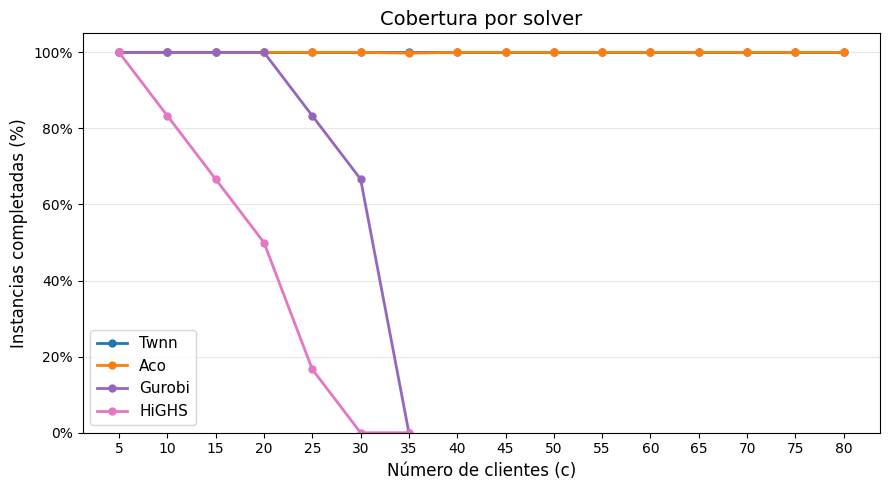

In [128]:
fig, ax = plt.subplots(figsize=(9, 5))

all_c = sorted(df_aco["c"].unique())

for solver, df in dfs.items():
    coverage = (
        df.assign(finished=(df["status"] == "finished"))
        .groupby("c")["finished"]
        .mean() * 100
    )
    ax.plot(
        coverage.index,
        coverage.values,
        marker="o",
        label=SOLVER_LABELS[solver],
        color=SOLVER_COLORS[solver],
        linewidth=2,
        markersize=5,
    )

ax.set_xlabel("Número de clientes (c)", fontsize=12)
ax.set_ylabel("Instancias completadas (%)", fontsize=12)
ax.set_title("Cobertura por solver", fontsize=14)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xticks(all_c)
ax.set_ylim(0, 105)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [129]:
# aco_feasible_avg = (                                                                                                                                                                  
#       df_combined[                                                                                                                                                                      
#           (df_combined['solver'] == SOLVER_ACO) &                                                                                                                                       
#           (df_combined['feasible'] == True) &
#           (df_combined['valid'] == True)                                                                                                                                                
#       ]           
#       .groupby(['c', 'v'], as_index=False)[['runtime', 'cost', 'ram_usage', 'cpu_usage']]
#       .mean()                                                                                                                                                                           
#   )

# solvers_feasibility_cmb = {
#     #"SOLVER_ACO": #df_combined[(df_combined['solver'] == SOLVER_ACO) & (df_combined['feasible'] == True) & (df_combined['valid'] == True)],
#     SOLVER_TWNN: df_combined[(df_combined['solver'] == SOLVER_TWNN) & (df_combined['feasible'] == True) & (df_combined['valid'] == True)],
#     SOLVER_ACO: aco_feasible_avg,
#     SOLVER_MILP_REFERENCE: (df_combined[(df_combined['solver'] == SOLVER_MILP_REFERENCE) & (df_combined['feasible'] == True) & (df_combined['valid'] == True)]      
#                 .groupby(['c', 'v'], as_index=False)[['runtime', 'cost', 'ram_usage', 'cpu_usage']]
#                 .mean()),
# }

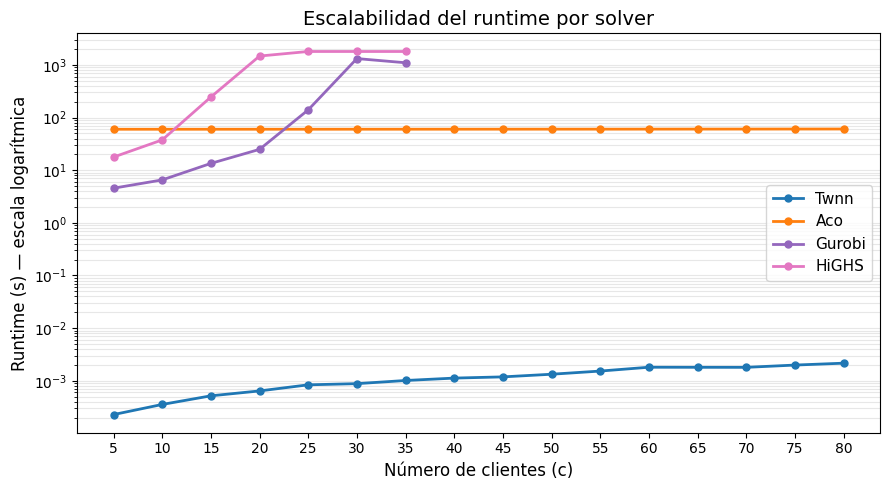

In [130]:
fig, ax = plt.subplots(figsize=(9, 5))

for solver, df in dfs.items():
    if solver == SOLVER_ACO:
        df = df.groupby(["c", "v"])["runtime"].mean().reset_index()
    median_runtime = df.groupby("c")["runtime"].median()
    ax.plot(
        median_runtime.index,
        median_runtime.values,
        marker="o",
        label=SOLVER_LABELS[solver],
        color=SOLVER_COLORS[solver],
        linewidth=2,
        markersize=5,
    )

ax.set_yscale("log")
ax.set_xlabel("Número de clientes (c)", fontsize=12)
ax.set_ylabel("Runtime (s) — escala logarítmica", fontsize=12)
ax.set_title("Escalabilidad del runtime por solver", fontsize=14)
ax.set_xticks(sorted(df_aco["c"].unique()))
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3, which="both")
plt.tight_layout()
plt.show()


/tmp/ipykernel_4993/1568058343.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


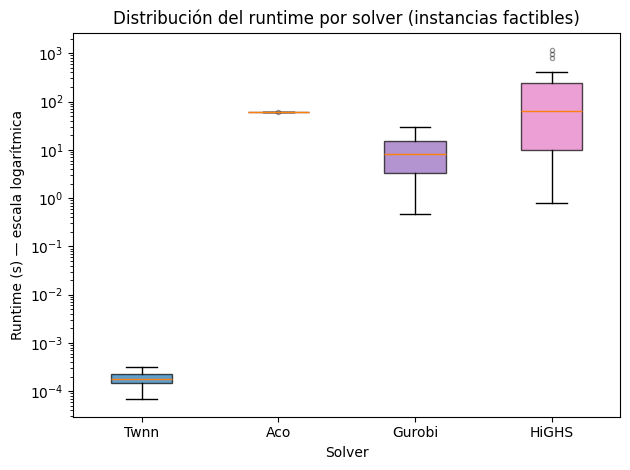

In [131]:
fig, ax = plt.subplots()

data_list = [data["runtime"] for _, data in solvers_commun_feasibility.items()]
labels = [SOLVER_LABELS[solver] for solver, _ in solvers_commun_feasibility.items()]
colors = [SOLVER_COLORS[solver] for solver, _ in solvers_commun_feasibility.items()]

bp = ax.boxplot(
    data_list,
    labels=labels,
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_yscale("log")
ax.set_title("Distribución del runtime por solver (instancias factibles)")
ax.set_xlabel("Solver")
ax.set_ylabel("Runtime (s) — escala logarítmica")

plt.tight_layout()
plt.show()

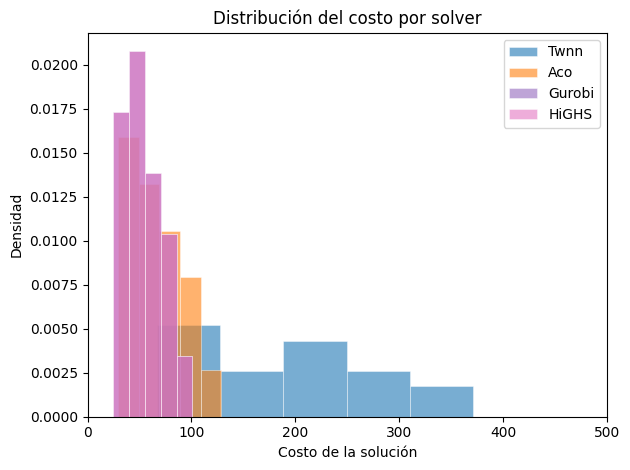

In [132]:
fig, ax = plt.subplots()

for solver, data in solvers_commun_feasibility.items():
    ax.hist(
        data["cost"],
        bins=5,
        color=SOLVER_COLORS[solver],
        edgecolor="white",
        linewidth=0.5,
        alpha=0.6,
        density=True,
        label=SOLVER_LABELS[solver],
    )

ax.set_title("Distribución del costo por solver")
ax.set_xlabel("Costo de la solución")
ax.set_ylabel("Densidad")
ax.legend()
ax.set_xlim(0, 500)

plt.tight_layout()
plt.show()

Es una versión suavizada del histograma. En lugar de apilar barras por bins, coloca una campana gaussiana sobre cada punto y las suma. El resultado es una curva continua que estima la distribución del costo. La altura representa densidad de probabilidad — picos altos = esa zona de costos es muy frecuente.

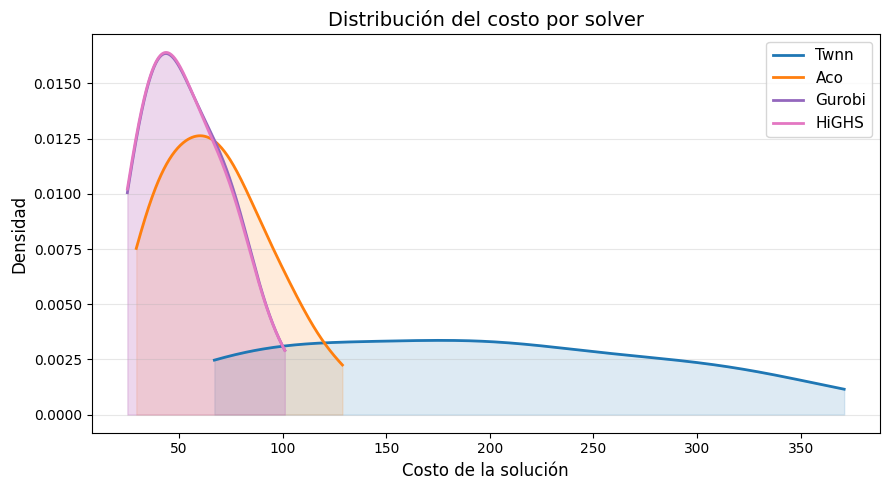

In [133]:
fig, ax = plt.subplots(figsize=(9, 5))

for solver, data in solvers_commun_feasibility.items():
    costs = data["cost"].values
    if len(costs) < 2:
        continue
    kde = gaussian_kde(costs)
    x = np.linspace(costs.min(), costs.max(), 300)
    ax.plot(x, kde(x), label=SOLVER_LABELS[solver], color=SOLVER_COLORS[solver], linewidth=2)
    ax.fill_between(x, kde(x), alpha=0.15, color=SOLVER_COLORS[solver])

ax.set_title("Distribución del costo por solver", fontsize=14)
ax.set_xlabel("Costo de la solución", fontsize=12)
ax.set_ylabel("Densidad", fontsize=12)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

/tmp/ipykernel_4993/839240103.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


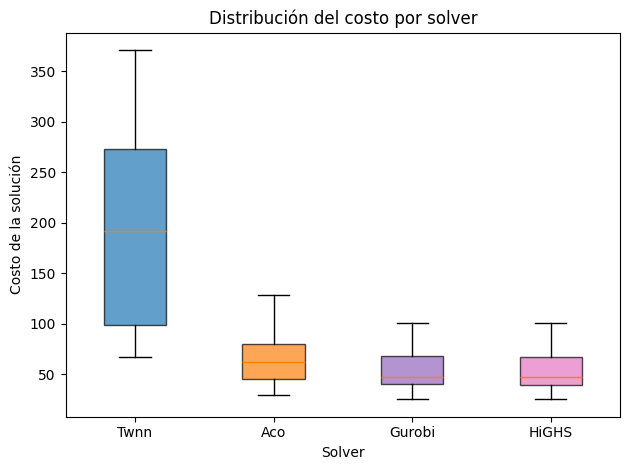

In [134]:
fig, ax = plt.subplots()

data_list = [data["cost"] for _, data in solvers_commun_feasibility.items()]

bp = ax.boxplot(
    data_list,
    labels=[SOLVER_LABELS[solver] for solver, _ in dfs.items()],
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, color in zip(bp["boxes"], [SOLVER_COLORS[solver] for solver, _ in dfs.items()]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

ax.set_title("Distribución del costo por solver")
ax.set_xlabel("Solver")
ax.set_ylabel("Costo de la solución")

plt.tight_layout()
plt.show()

/tmp/ipykernel_4993/4145786491.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


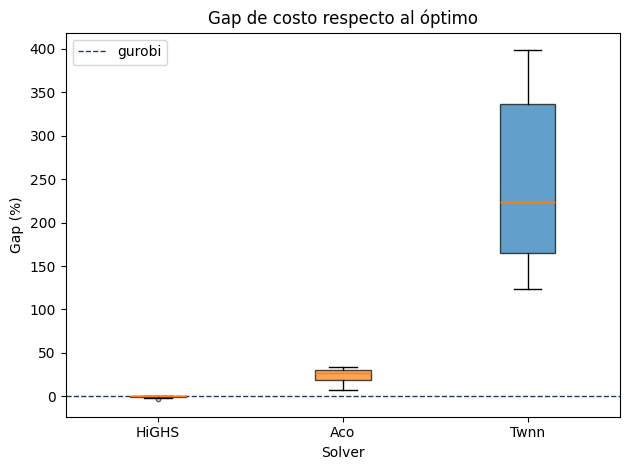

HiGHS: media=-0.6%, std=1.1%, mediana=0.0%
Aco: media=24.3%, std=8.3%, mediana=26.7%
Twnn: media=253.0%, std=93.6%, mediana=224.0%


In [135]:
gurobi_ok   = solvers_commun_feasibility[SOLVER_MILP_REFERENCE][["c", "v", "cost"]].rename(columns={"cost": "gurobi_cost"})
aco_mean  = solvers_commun_feasibility[SOLVER_ACO][["c", "v", "cost"]].rename(columns={"cost": "cost_aco"})
twnn_ok     = solvers_commun_feasibility[SOLVER_TWNN][["c", "v", "cost"]].rename(columns={"cost": "cost_twnn"})
highs_ok  = solvers_commun_feasibility[SOLVER_MILP_SCND][["c", "v", "cost"]].rename(columns={"cost": "cost_highs"})

gap_df = gurobi_ok.merge(aco_mean, on=["c", "v"]).merge(twnn_ok, on=["c", "v"]).merge(highs_ok, on=["c", "v"])
gap_df["gap_aco"]   = (gap_df["cost_aco"]   - gap_df["gurobi_cost"]) / gap_df["gurobi_cost"] * 100
gap_df["gap_twnn"]    = (gap_df["cost_twnn"]    - gap_df["gurobi_cost"]) / gap_df["gurobi_cost"] * 100
gap_df["gap_highs"] = (gap_df["cost_highs"] - gap_df["gurobi_cost"]) / gap_df["gurobi_cost"] * 100

solvers_gap = [
    ("gap_highs", SOLVER_MILP_SCND),
    ("gap_aco",   SOLVER_ACO),
    ("gap_twnn",    SOLVER_TWNN),
]

fig, ax = plt.subplots()

bp = ax.boxplot(
    [gap_df[col] for col, _ in solvers_gap],
    labels=[SOLVER_LABELS[s] for _, s in solvers_gap],
    patch_artist=True,
    flierprops=dict(marker="o", markersize=3, alpha=0.4),
)

for patch, (_, solver) in zip(bp["boxes"], solvers_gap):
    patch.set_facecolor(SOLVER_COLORS[solver])
    patch.set_alpha(0.7)

ax.axhline(0, color="#1a3d61", linestyle="--", linewidth=1, label=SOLVER_MILP_REFERENCE)
ax.set_title("Gap de costo respecto al óptimo")
ax.set_xlabel("Solver")
ax.set_ylabel("Gap (%)")
ax.legend()

plt.tight_layout()
plt.show()

for col, solver in solvers_gap:
    print(f"{SOLVER_LABELS[solver]}: media={gap_df[col].mean():.1f}%, std={gap_df[col].std():.1f}%, mediana={gap_df[col].median():.1f}%")

In [136]:
summary = pd.DataFrame({
    SOLVER_LABELS[solver]: {
        "Mínimo":  gap_df[col].min(),
        "Máximo":  gap_df[col].max(),
        "Promedio": gap_df[col].mean(),
    }
    for col, solver in solvers_gap
}).round(1)

print(summary.to_string())
# print(summary.to_latex(float_format="%.1f"))

          HiGHS   Aco   Twnn
Mínimo     -3.3   7.8  123.3
Máximo      0.0  34.1  398.3
Promedio   -0.6  24.3  253.0


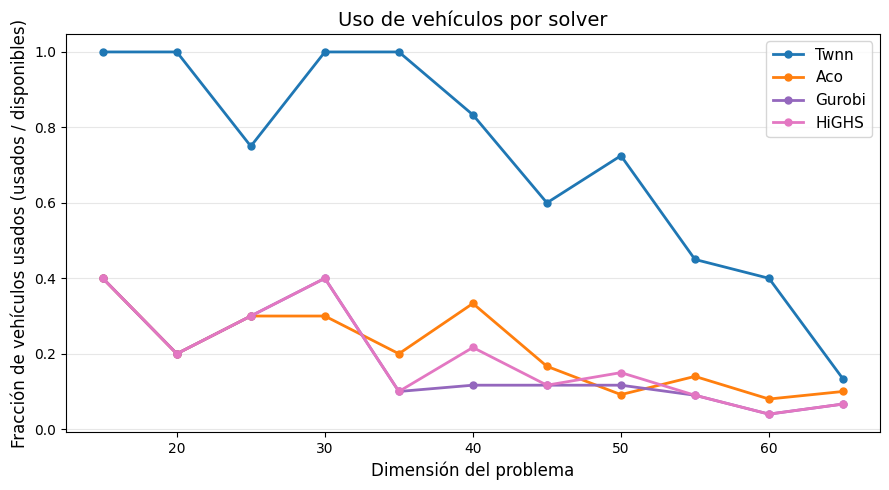

In [143]:
def n_vehicles(routes):
    if routes is None:
        return None
    return len(routes)

fig, ax = plt.subplots(figsize=(9, 5))

for solver, df in solvers_commun_feasibility.items():
    df["n_vehicles"] = df["routes"].apply(n_vehicles)
    df["veh_ratio"]  = df["n_vehicles"] / df["v"]

    scatter = df.groupby("dim")["veh_ratio"].median()
    ax.plot(
        scatter.index,
        scatter.values,
        marker="o",
        label=SOLVER_LABELS[solver],
        color=SOLVER_COLORS[solver],
        linewidth=2,
        markersize=5,
    )

ax.set_xlabel("Dimensión del problema", fontsize=12)
ax.set_ylabel("Fracción de vehículos usados (usados / disponibles)", fontsize=12)
ax.set_title("Uso de vehículos por solver", fontsize=14)
ax.legend(fontsize=11)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

a medida que fui introduciendo nuevos modulos a aco, se fue aproximando al ratio de milp. antes estaba mas cerca del ratio de twnn porque comenzaban igual.

In [168]:
import networkx as nx
import json

def build_graph(routes):
    if isinstance(routes, str):
        routes = json.loads(routes)
    G = nx.DiGraph()
    for route in routes.values():
        for i in range(len(route) - 1):
            G.add_edge(route[i], route[i+1])
    return G, routes

def plot_routes_comparison(instance_row_per_solver: dict, title_prefix=""):
    """instance_row_per_solver: {solver_name: row_df_con_routes}"""

    # Layout compartido basado en la union de todos los grafos
    all_nodes = set()
    for row in instance_row_per_solver.values():
        routes = json.loads(row["routes"]) if isinstance(row["routes"], str) else row["routes"]
        for route in routes.values():
            all_nodes.update(route)

    G_union = nx.Graph()
    G_union.add_nodes_from(all_nodes)
    pos = nx.spring_layout(G_union, seed=42)

    n_solvers = len(instance_row_per_solver)
    fig, axes = plt.subplots(1, n_solvers, figsize=(7 * n_solvers, 6))
    if n_solvers == 1:
        axes = [axes]

    colors = plt.cm.tab10.colors

    for ax, (solver, row) in zip(axes, instance_row_per_solver.items()):
        routes = json.loads(row["routes"]) if isinstance(row["routes"], str) else row["routes"]

        depot_start = set()
        depot_end   = set()
        customers   = set()
        for route in routes.values():
            depot_start.add(route[0])
            depot_end.add(route[-1])
            customers.update(route[1:-1])

        G, _ = build_graph(routes)

        # Aristas coloreadas por ruta
        for i, route in enumerate(routes.values()):
            edges = [(route[j], route[j+1]) for j in range(len(route) - 1)]
            nx.draw_networkx_edges(G, pos, edgelist=edges,
                                    edge_color=[colors[i % len(colors)]],
                                    arrows=True, ax=ax, width=1.8,
                                    arrowsize=12, connectionstyle="arc3,rad=0.1")

        # Nodos
        nx.draw_networkx_nodes(G, pos, nodelist=list(depot_start),
                                node_shape="s", node_color="black", node_size=250, ax=ax)
        nx.draw_networkx_nodes(G, pos, nodelist=list(depot_end),
                                node_shape="^", node_color="black", node_size=250, ax=ax)
        nx.draw_networkx_nodes(G, pos, nodelist=list(customers),
                                node_shape="o", node_color="steelblue", node_size=120, ax=ax)
        nx.draw_networkx_labels(G, pos, ax=ax, font_size=6, font_color="white")

        ax.set_title(f"{title_prefix} — {SOLVER_LABELS.get(solver, solver)}\n"
                    f"{len(routes)} vehículos usados", fontsize=12)
        
        ax.set_title(f"{title_prefix} — {SOLVER_LABELS.get(solver, solver)}\n"
                    f"{len(routes)} vehículos usados | costo: {row['cost']:.1f}", fontsize=12)
        ax.axis("off")

    # Leyenda
    depot_patch  = plt.Line2D([0], [0], marker="s", color="w", markerfacecolor="black",
                                markersize=10, label="Depot")
    return_patch = plt.Line2D([0], [0], marker="^", color="w", markerfacecolor="black",
                                markersize=10, label="Return")
    customer_patch = plt.Line2D([0], [0], marker="o", color="w", markerfacecolor="steelblue",
                                markersize=8, label="Cliente")
    fig.legend(handles=[depot_patch, return_patch, customer_patch], loc="lower center",
                ncol=3, fontsize=11, bbox_to_anchor=(0.5, -0.02))


    plt.tight_layout()
    plt.show()


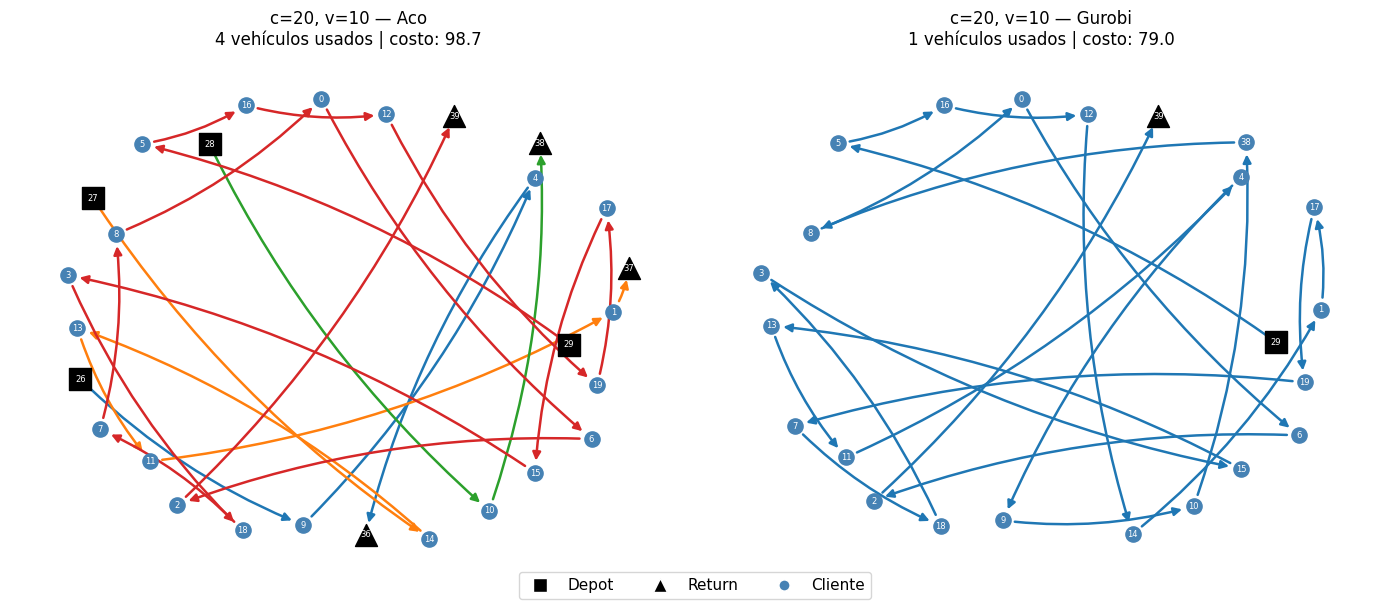

In [169]:
C, V = 20, 10  # instancia a visualizar

rows = {}
for solver, df in solvers_commun_feasibility.items():
    if solver in [SOLVER_TWNN, SOLVER_MILP_SCND]:
        continue
    match = df[(df["c"] == C) & (df["v"] == V)]
    if not match.empty:
        rows[solver] = match.iloc[0]

plot_routes_comparison(rows, title_prefix=f"c={C}, v={V}")


esta bien asi o algo mejor de este estilo /home/tmarmay/Pictures/Screenshots/vrp.png

![asd](../../../../../Pictures/Screenshots/vrp.png)